In [1]:
import pandas as pd

train_df = pd.read_csv("./sample/train.csv")
test_df = pd.read_csv("./sample/test.csv")

In [2]:
train = train_df.copy()
test = test_df.copy()

In [3]:
test.head(2)

,ID,A2M,AAAS,AADAT,AARS1,ABAT,ABCA1,ABCA2,ABCA3,ABCA4,...,ZNF292,ZNF365,ZNF639,ZNF707,ZNFX1,ZNRF4,ZPBP,ZW10,ZWINT,ZYX
0,TEST_0000,WT,WT,WT,WT,WT,WT,WT,WT,WT,...,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT
1,TEST_0001,WT,WT,WT,WT,WT,R587Q,WT,WT,WT,...,WT,WT,WT,WT,WT,I383Sfs,WT,WT,WT,WT


In [4]:
train.head(3)

,ID,SUBCLASS,A2M,AAAS,AADAT,AARS1,ABAT,ABCA1,ABCA2,ABCA3,...,ZNF292,ZNF365,ZNF639,ZNF707,ZNFX1,ZNRF4,ZPBP,ZW10,ZWINT,ZYX
0,TRAIN_0000,KIPAN,WT,WT,WT,WT,WT,WT,WT,WT,...,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT
1,TRAIN_0001,SARC,WT,WT,WT,WT,WT,WT,WT,WT,...,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT
2,TRAIN_0002,SKCM,R895R,WT,WT,WT,WT,WT,WT,WT,...,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT


In [5]:
print(train.isnull().any().any())

# 컬럼별 결측치 개수 확인
missing_counts = train_df.isnull().sum()

# 결측치가 0보다 큰 컬럼만 모아서 출력
print(missing_counts[missing_counts > 0])

False
Series([], dtype: int64)


In [6]:
# train.csv에서 'ID'와 'SUBCLASS'를 제외한 모든 컬럼에서 'WT'가 아닌 고유 값들 확인
gene_cols = [col for col in train.columns if col not in ['ID', 'SUBCLASS']]
unique_mutations = set()
for col in gene_cols:
    unique_vals = train[col].dropna().unique()
    for val in unique_vals:
        if val != 'WT':
            unique_mutations.add(val)

print(sorted(list(unique_mutations)))

['*103*', '*1070*', '*111*', '*1119*', '*115*', '*1182*', '*1217*', '*1232*', '*1232* P359S E201E P981S *1232* P359S E201E P981S', '*129*', '*134*', '*141*', '*1503*', '*1574* R534*', '*1802*', '*184*', '*194* E172Q', '*194* R168T', '*197*', '*199*', '*214fs', '*220* D160N *220* D160N', '*227*', '*229* N37S', '*239*', '*261*', '*261* K45E', '*268*', '*311*', '*326*', '*329*', '*332*', '*334* E321D D266N D265N D253N', '*335*', '*340*', '*347*', '*366*', '*373*', '*385* F125Y', '*402*', '*407*', '*429*', '*430*', '*436*', '*444fs', '*459*', '*459* *459*', '*481*', '*484*', '*487* R437Q', '*488*', '*505*', '*510*', '*517*', '*534* G294E', '*544*', '*554*', '*579*', '*586* Q578H', '*589*', '*608* I2I', '*621*', '*633*', '*670*', '*680*', '*682*', '*742*', '*781*', '*783*', '*786*', '*856*', '*92*', '*924*', '*931*', '*990*', '-101fs', '-1093fs', '-1295fs', '-1456fs', '-148fs', '-151fs', '-165fs', '-166fs', '-16fs', '-178fs', '-1956fs', '-1985fs', '-202fs', '-203fs', '-220fs', '-222fs', '-2

# 데이터 전처리 (결측치, 이상치, 문자열 데이터 치환 등)

In [7]:
# 1. WT = 0, synonymous = 1, missence = 2, nonsence = 3로 치환

import re
import numpy as np

def encode_token(t: str) -> int:
    """변이 하나를 0~3 점수로 변환"""
    if 'fs' in t:                                   # frameshift
        return 3
    if '>' in t:                                    # 355_356QG>H*, 91_92NH>KY
        left, right = t.split('>')
        left = re.sub(r'^[\d_\-]+', '', left)
        if right.endswith('*'):
            return 3
        return 1 if left == right else 2
    if re.fullmatch(r'[A-Z]\d+\*', t):              # nonsense
        return 3
    if re.fullmatch(r'\*\d+\*', t):                 # 종결코돈 유지
        return 1
    if 'del' in t or 'ins' in t:                    # in-frame 결실/삽입: R649del, G103_K104insFF, G2327delinsVC
        return 3 if t.endswith('*') else 2          # 삽입된 서열에 종결코돈이 있으면 절단
    m = re.fullmatch(r'([A-Z])\d+([A-Z])', t)       # 단일 아미노산 치환
    if m:
        return 1 if m.group(1) == m.group(2) else 2
    return -1                                # 해석 못한 형식 확인용

def encode_cell(v: str) -> int:
    if v == 'WT':
        return 0
    return max(encode_token(t) for t in v.split())  # 변이가 여러 개면 최댓값

gene_cols = train_df.columns[2:]                    # ID, SUBCLASS 제외

# 고유 문자열만 변환한 뒤 매핑 (칸마다 함수를 돌리는 것보다 훨씬 빠름)
uniq = pd.unique(train[gene_cols].values.ravel())
mapping = {v: encode_cell(v) for v in uniq}

X = train[gene_cols].apply(lambda col: col.map(mapping)).astype(np.int8)
y = train['SUBCLASS']

assert (X == -1).sum().sum() == 0, "해석 못한 변이 있음"
print(X.shape)

(6201, 4384)


In [8]:
!pip install lightgbm -q


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [9]:
# lightGBM 모델

import numpy as np
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report

# 1. 라벨 인코딩
le = LabelEncoder()
y_enc = le.fit_transform(y)                     # 26개 암종 -> 0~25

# 2. 환자 단위 변이 수(TMB 대용) - 행 단위 계산이라 누수 걱정 없음
tmb = (X > 0).sum(axis=1).values.reshape(-1, 1)

# 3. train / valid 분할 (암종 비율 유지)
X_tr, X_va, y_tr, y_va, tmb_tr, tmb_va = train_test_split(
    X, y_enc, tmb, test_size=0.2, stratify=y_enc, random_state=42
)

# 4. 최소 빈도 필터: train 기준으로만 계산 (valid 정보가 새지 않게)
MIN_COUNT = 3
keep = ((X_tr > 0).sum(axis=0) >= MIN_COUNT).values
gene_names = np.array(X.columns)[keep].tolist()
print(f"유전자 {X.shape[1]} -> {keep.sum()}개 사용")

Xtr = np.hstack([X_tr.values[:, keep], tmb_tr]).astype(np.float32)
Xva = np.hstack([X_va.values[:, keep], tmb_va]).astype(np.float32)
feature_names = gene_names + ['TMB']

유전자 4384 -> 4205개 사용


In [10]:
from collections import Counter
from scipy import sparse

# 1. train/valid 환자의 원본 변이 문자열 (인덱스로 분할과 맞춤)
raw_tr = train.loc[X_tr.index, gene_cols]
raw_va = train.loc[X_va.index, gene_cols]

def extract_variants(raw, skip_syn=True):
    """(환자 행번호, '유전자|변이') 쌍 목록. WT와 침묵 변이는 제외"""
    vals, genes = raw.values, raw.columns.values
    r, c = np.nonzero(vals != 'WT')
    pairs = []
    for i, j in zip(r, c):
        for t in vals[i, j].split():                 # 한 칸에 변이가 여러 개여도 각각 처리
            if skip_syn and re.fullmatch(r'([A-Z])\d+\1', t):
                continue
            pairs.append((i, f"{genes[j]}|{t}"))
    return pairs

def to_sparse(pairs, n_rows, vocab):
    rows, cols = [], []
    for i, f in pairs:
        k = vocab.get(f)
        if k is not None:
            rows.append(i); cols.append(k)
    M = sparse.csr_matrix(
        (np.ones(len(rows), dtype=np.float32), (rows, cols)),
        shape=(n_rows, len(vocab)),
    )
    M.data[:] = 1
    return M

# 2. 어휘(vocab)는 train에서만 만든다 (누수 방지)
MIN_VAR = 5
pairs_tr = extract_variants(raw_tr)
pairs_va = extract_variants(raw_va)

cnt = Counter(f for _, f in pairs_tr)
var_names = [f for f, n in cnt.items() if n >= MIN_VAR]
vocab = {f: k for k, f in enumerate(var_names)}
print(f"{len(cnt)}종 변이 -> {len(vocab)}개 사용")

V_tr = to_sparse(pairs_tr, len(raw_tr), vocab)
V_va = to_sparse(pairs_va, len(raw_va), vocab)

# 3. 기존 특징(유전자 점수 + TMB)에 이어 붙이기
Xtr2 = sparse.hstack([sparse.csr_matrix(Xtr), V_tr]).tocsr()
Xva2 = sparse.hstack([sparse.csr_matrix(Xva), V_va]).tocsr()
feature_names2 = feature_names + var_names
print(Xtr2.shape, Xva2.shape)

137742종 변이 -> 273개 사용
(4960, 4479) (1241, 4479)


In [11]:
# 5. LightGBM 학습
model = lgb.LGBMClassifier(
    objective='multiclass',
    n_estimators=2000,
    learning_rate=0.05,
    num_leaves=15,
    min_child_samples=5,            # 희귀 변이를 잡을 수 있게 작게
    colsample_bytree=0.3,           # 특징이 많아서 일부만 샘플링 (속도와 과적합 방지)
    subsample=0.8,
    subsample_freq=1,
    reg_lambda=1.0,
    class_weight='balanced',        # 암종 불균형 보정
    random_state=42,
    n_jobs=-1,
    verbose=-1,
)

model.fit(
    Xtr2, y_tr,
    eval_set=[(Xva2, y_va)],
    eval_metric='multi_logloss',
    callbacks=[lgb.early_stopping(50), lgb.log_evaluation(50)],
)


/Users/admin/project/oz-07/Dacon-AI-Healthcare-Hackathon/.venv/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 50 rounds
[50]	valid_0's multi_logloss: 2.02164
[100]	valid_0's multi_logloss: 1.8601
[150]	valid_0's multi_logloss: 1.81398
[200]	valid_0's multi_logloss: 1.80884
Early stopping, best iteration is:
[190]	valid_0's multi_logloss: 1.8075


,num_leaves,15
,learning_rate,0.05
,n_estimators,2000
,objective,'multiclass'
,class_weight,'balanced'
,min_child_samples,5
,subsample,0.8
,subsample_freq,1
,colsample_bytree,0.3
,reg_lambda,1.0
,random_state,42


In [12]:
# 6. 평가
pred = model.predict(Xva2)
print("Accuracy :", accuracy_score(y_va, pred))
print("Macro F1 :", f1_score(y_va, pred, average='macro'))
print(classification_report(y_va, pred, target_names=le.classes_, zero_division=0))

# 7. 중요 유전자 확인 (빈도 통계/알려진 암 유전자와 비교용)
imp = pd.Series(
    model.booster_.feature_importance(importance_type='gain'),
    index=feature_names2
).sort_values(ascending=False)
print(imp.head(20))

Accuracy : 0.39403706688154716
Macro F1 : 0.4118588227838015
              precision    recall  f1-score   support

         ACC       1.00      0.79      0.88        14
        BLCA       0.83      0.24      0.37        21
        BRCA       0.81      0.38      0.51       157
        CESC       0.13      0.16      0.14        31
        COAD       0.87      0.60      0.71        45
        DLBC       1.00      0.29      0.44         7
      GBMLGG       0.44      0.23      0.30        92
        HNSC       0.38      0.31      0.34        45
       KIPAN       0.15      0.15      0.15       103
        KIRC       0.22      0.30      0.25        67
        LAML       0.53      0.53      0.53        32
         LGG       0.38      0.63      0.48        46
        LIHC       0.35      0.42      0.38        31
        LUAD       0.36      0.27      0.31        37
        LUSC       0.32      0.33      0.33        36
          OV       0.21      0.45      0.29        51
        PAAD       0

In [13]:
!pip install matplotlib seaborn -q


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


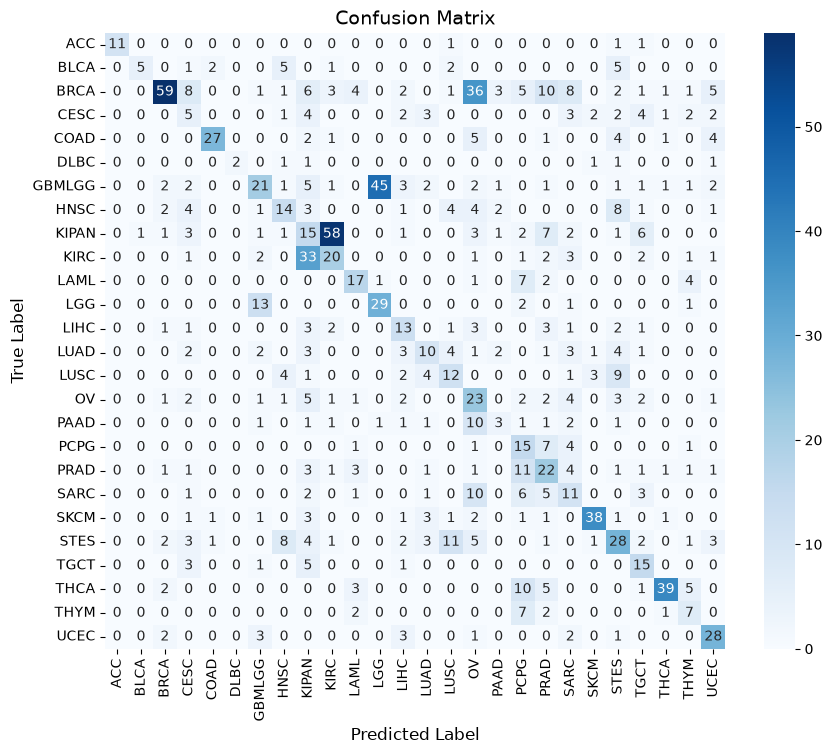

In [14]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Confusion Matrix 계산
cm = confusion_matrix(y_va, pred)

# 3. 시각화 크기 설정 및 그리기
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm, 
    annot=True,          # 칸 안에 숫자 표시
    fmt='d',             # 정수 형태로 표시
    cmap='Blues',        # 색상 테마
    xticklabels=le.classes_, # 혹은 고유 클래스 리스트
    yticklabels=le.classes_
)

plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.title('Confusion Matrix', fontsize=14)
plt.show()

In [15]:
merge = {'LGG': 'GBMLGG', 'KIRC': 'KIPAN'}
yt = pd.Series(le.inverse_transform(y_va)).replace(merge)
yp = pd.Series(le.inverse_transform(pred)).replace(merge)
print("Accuracy:", accuracy_score(yt, yp))
print("Macro F1:", f1_score(yt, yp, average='macro'))

Accuracy: 0.5141015310233682
Macro F1: 0.46066687401686196


In [16]:
PATHWAYS = {
    # TCGA 발암 신호경로 (문헌 기반, 기억으로 정리: 검증 필요)
    'cell_cycle': ['CDKN1A','CDKN1B','CDKN2A','CDKN2B','CDKN2C','CCND1','CCND2','CCND3','CCNE1','CDK2','CDK4','CDK6','RB1','E2F1','E2F2','E2F3'],
    'hippo': ['NF2','LATS1','LATS2','SAV1','MOB1A','MOB1B','STK3','STK4','YAP1','WWTR1','TEAD1','TEAD2','TEAD3','TEAD4','FAT1','FAT2','FAT3','FAT4','AMOT','AMOTL1','AMOTL2','WWC1','TAOK1'],
    'myc': ['MYC','MYCL','MYCN','MAX','MGA'],
    'notch': ['NOTCH1','NOTCH2','NOTCH3','NOTCH4','JAG1','JAG2','DLL1','DLL3','DLL4','FBXW7','NCSTN','PSEN1','PSEN2','MAML1','MAML2','MAML3','RBPJ','SPEN','NUMB','HES1','HEY1'],
    'nrf2': ['NFE2L2','KEAP1','CUL3'],
    'pi3k': ['PIK3CA','PIK3CB','PIK3R1','PIK3R2','PTEN','AKT1','AKT2','AKT3','MTOR','TSC1','TSC2','STK11','RICTOR','RPTOR','INPP4B','PDPK1','FOXO1','FOXO3'],
    'rtk_ras': ['EGFR','ERBB2','ERBB3','ERBB4','FGFR1','FGFR2','FGFR3','FGFR4','MET','KIT','PDGFRA','PDGFRB','RET','ALK','ROS1','NTRK1','NTRK2','NTRK3','IGF1R','FLT3','KRAS','HRAS','NRAS','BRAF','RAF1','ARAF','MAP2K1','MAP2K2','MAPK1','NF1','SOS1','PTPN11','RASA1','RASA2','SPRED1','RIT1'],
    'tgfb': ['TGFBR1','TGFBR2','ACVR1B','ACVR2A','SMAD2','SMAD3','SMAD4','BMPR1A','BMPR2','SMAD1'],
    'p53': ['TP53','MDM2','MDM4','ATM','CHEK1','CHEK2','PPM1D','TP53BP1','RPS6KA3'],
    'wnt': ['CTNNB1','APC','AXIN1','AXIN2','GSK3B','TCF7L2','LEF1','RNF43','ZNRF3','SOX9','AMER1','FAM123B','CSNK1A1','TCF7'],
    # 추가 경로
    'hr_repair': ['BRCA1','BRCA2','PALB2','ATR','RAD50','RAD51','RAD51B','RAD51C','RAD51D','RAD54L','MRE11','NBN','BARD1','BRIP1','FANCA','FANCC','FANCD2','FANCE','FANCF','FANCG','FANCI','FANCL','FANCM','XRCC2','XRCC3','FAM175A','ABRAXAS1'],
    'mismatch_repair': ['MLH1','MLH3','MSH2','MSH3','MSH6','PMS1','PMS2','POLE','POLD1','EXO1'],
    'swi_snf': ['ARID1A','ARID1B','ARID2','SMARCA4','SMARCB1','SMARCA2','PBRM1','SMARCC1','SMARCC2','SMARCD1','BRD7'],
    'epigenetic': ['KMT2A','KMT2B','KMT2C','KMT2D','SETD2','NSD1','NSD2','EZH2','KDM6A','KDM5C','DNMT3A','DNMT1','TET1','TET2','ASXL1','BAP1','ATRX','DAXX','IDH1','IDH2','CREBBP','EP300','H3F3A','H3-3A'],
    'hypoxia_sdh': ['SDHA','SDHB','SDHC','SDHD','SDHAF2','FH','VHL','EPAS1','EGLN1','EGLN2','HIF1A','MDH2','MAX','TMEM127','KIF1B'],
    'cohesin': ['STAG1','STAG2','SMC1A','SMC3','RAD21','NIPBL'],
    'splicing': ['SF3B1','U2AF1','SRSF2','ZRSR2','SF1','PRPF8'],
    'apoptosis': ['BCL2','BCL2L1','MCL1','BAX','BAK1','BAD','BID','CASP8','CASP3','CASP9','FADD','FAS','XIAP','BIRC2','BIRC3','CFLAR'],
    'antigen_immune': ['B2M','HLA-A','HLA-B','HLA-C','TAP1','TAP2','JAK1','JAK2','STAT1','IFNGR1','IFNGR2','CIITA'],
    'jak_stat': ['JAK1','JAK2','JAK3','STAT3','STAT5B','SOCS1'],
    'nfkb': ['NFKB1','NFKB2','RELA','TRAF2','TRAF3','CYLD','TNFAIP3','MAP3K14','IKBKB','CARD11','MYD88'],
    # 길이가 긴 유전자(배경 변이가 잘 잡힘): 변이 패턴 대용
    'long_genes': ['TTN','MUC16','RYR2','RYR1','RYR3','SYNE1','SYNE2','OBSCN','PCLO','USH2A','LRP1B','CSMD1','CSMD3','DNAH5','DNAH10','FLG','HMCN1','MUC5B','APOB','ZFHX4'],
}

def build_pathway_index(gene_cols, min_genes=2):
    gi = {g: i for i, g in enumerate(gene_cols)}
    idx = {k: np.array(sorted({gi[g] for g in v if g in gi})) for k, v in PATHWAYS.items()}
    return {k: v for k, v in idx.items() if len(v) >= min_genes}   # 데이터에 2개 미만이면 제외

def pathway_features(Xd, pw_idx):
    v = Xd.values
    cols = []
    for name, idx in pw_idx.items():
        sub = v[:, idx]
        cols.append((sub >= 2).sum(1))          # 경로 내 변이(침묵 제외) 유전자 수
        cols.append((sub == 3).sum(1))          # 경로 내 절단 변이 유전자 수
        cols.append((sub >= 2).any(1))          # 경로 내 변이 유무
    return np.column_stack(cols).astype(np.float32)

pw_idx = build_pathway_index(list(gene_cols))
print("사용 경로:", len(pw_idx), "->", {k: len(v) for k, v in pw_idx.items()})

USE_PATHWAY = True

def dense_features(Xd, keep):
    v = Xd.values
    parts = [v[:, keep],
            (v > 0).sum(1, keepdims=True),            # TMB
            (v == 1).sum(1, keepdims=True),           # n_syn
            (v == 2).sum(1, keepdims=True),           # n_mis
            (v == 3).sum(1, keepdims=True)]           # n_trunc
    if USE_PATHWAY:
        parts.append(pathway_features(Xd, pw_idx))
    return np.hstack(parts).astype(np.float32)

사용 경로: 21 -> {'cell_cycle': 16, 'hippo': 7, 'myc': 2, 'notch': 17, 'nrf2': 2, 'pi3k': 14, 'rtk_ras': 23, 'tgfb': 9, 'p53': 6, 'wnt': 9, 'hr_repair': 11, 'mismatch_repair': 6, 'epigenetic': 8, 'hypoxia_sdh': 10, 'cohesin': 5, 'splicing': 2, 'apoptosis': 14, 'antigen_immune': 12, 'jak_stat': 4, 'nfkb': 8, 'long_genes': 4}


In [17]:
from sklearn.model_selection import StratifiedKFold

CW = 'balanced'
skf = StratifiedKFold(5, shuffle=True, random_state=42)

def build_features(tr_idx, va_idx, min_count=3, min_var=5):
    Xt, Xv = X.iloc[tr_idx], X.iloc[va_idx]
    keep = ((Xt > 0).sum(axis=0) >= min_count).values
    raw_t = train.iloc[tr_idx][gene_cols]
    raw_v = train.iloc[va_idx][gene_cols]
    pairs_t, pairs_v = extract_variants(raw_t), extract_variants(raw_v)
    cnt = Counter(f for _, f in pairs_t)
    vocab = {f: k for k, f in enumerate([f for f, n in cnt.items() if n >= min_var])}
    Vt = to_sparse(pairs_t, len(raw_t), vocab)
    Vv = to_sparse(pairs_v, len(raw_v), vocab)
    return (sparse.hstack([sparse.csr_matrix(dense_features(Xt, keep)), Vt]).tocsr(),
            sparse.hstack([sparse.csr_matrix(dense_features(Xv, keep)), Vv]).tocsr())

def make_folds():
    return [(tr, va, *build_features(tr, va)) for tr, va in skf.split(X, y_enc)]

def run_cv(class_weight, folds):
    oof = np.zeros((len(y_enc), 26))
    for tr, va, Xt, Xv in folds:
        m = lgb.LGBMClassifier(
            objective='multiclass', n_estimators=200, learning_rate=0.05,
            num_leaves=15, min_child_samples=5, colsample_bytree=0.3,
            subsample=0.8, subsample_freq=1, reg_lambda=1.0,
            class_weight=class_weight, random_state=42, n_jobs=-1, verbose=-1,
        )
        m.fit(Xt, y_enc[tr])
        oof[va] = m.predict_proba(Xv)
    return oof

USE_PATHWAY = False
oof_base = run_cv(CW, make_folds())      # 경로 특징 없음
USE_PATHWAY = True
oof_pw = run_cv(CW, make_folds())        # 경로 특징 있음

f_base = pd.Series(f1_score(y_enc, oof_base.argmax(1), average=None), index=le.classes_)
f_pw = pd.Series(f1_score(y_enc, oof_pw.argmax(1), average=None), index=le.classes_)
print("Macro F1  기존:", round(f_base.mean(), 4), " 경로 추가:", round(f_pw.mean(), 4))
print(pd.DataFrame({'기존': f_base, '경로 추가': f_pw}).round(3).loc[['CESC','PAAD','SARC','OV','PCPG']])

Macro F1  기존: 0.4145  경로 추가: 0.4173
         기존  경로 추가
CESC  0.142  0.189
PAAD  0.144  0.167
SARC  0.247  0.229
OV    0.371  0.372
PCPG  0.310  0.307


In [18]:
def tune_class_weights(P, y, n_iter=3):
    grid = np.exp(np.linspace(-1.5, 1.5, 13))
    w = np.ones(P.shape[1])
    best = f1_score(y, (P * w).argmax(1), average='macro')
    for _ in range(n_iter):
        for c in range(P.shape[1]):
            for g in grid:
                w2 = w.copy(); w2[c] = g
                s = f1_score(y, (P * w2).argmax(1), average='macro')
                if s > best:
                    best, w = s, w2
    return w, best

oof = oof_pw
w, best = tune_class_weights(oof, y_enc)
print("가중치 적용 OOF Macro F1 (튜닝에 쓴 데이터라 낙관적):", best)

가중치 적용 OOF Macro F1 (튜닝에 쓴 데이터라 낙관적): 0.43264760485456877


In [19]:
# 1. test 변환 (결측은 WT로 채움)
assert set(gene_cols) <= set(test.columns), "test 컬럼이 train과 다름"
test_raw = test[gene_cols].fillna('WT')
map_t = {v: encode_cell(v) for v in pd.unique(test_raw.values.ravel())}
X_test = test_raw.apply(lambda c: c.map(map_t)).astype(np.int8)
assert (X_test == -1).sum().sum() == 0, "해석 못한 변이 있음"

# 2. 특징 생성: 전체 train으로 필터/어휘를 만들고 test에 적용
def make_features(Xt, raw_t, Xv, raw_v, min_count=3, min_var=5):
    keep = ((Xt > 0).sum(axis=0) >= min_count).values
    pairs_t, pairs_v = extract_variants(raw_t), extract_variants(raw_v)
    cnt = Counter(f for _, f in pairs_t)
    vocab = {f: k for k, f in enumerate([f for f, n in cnt.items() if n >= min_var])}
    Vt = to_sparse(pairs_t, len(raw_t), vocab)
    Vv = to_sparse(pairs_v, len(raw_v), vocab)
    return (sparse.hstack([sparse.csr_matrix(dense_features(Xt, keep)), Vt]).tocsr(),
            sparse.hstack([sparse.csr_matrix(dense_features(Xv, keep)), Vv]).tocsr())

X_full, X_te = make_features(X, train[gene_cols], X_test, test_raw)
print(X_full.shape, X_te.shape)          # 열 수가 같아야 함

# 3. 전체 train으로 학습 (seed 3개 평균으로 안정화)
P_test = np.zeros((X_te.shape[0], 26))
seeds = [42, 43, 44]
for s in seeds:
    m = lgb.LGBMClassifier(
        objective='multiclass', n_estimators=220, learning_rate=0.05,
        num_leaves=15, min_child_samples=5, colsample_bytree=0.3,
        subsample=0.8, subsample_freq=1, reg_lambda=1.0,
        class_weight=CW, random_state=s, n_jobs=-1, verbose=-1,
    )
    m.fit(X_full, y_enc)
    P_test += m.predict_proba(X_te) / len(seeds)

# 4. 클래스별 가중치를 곱해서 최종 예측
pred_test = (P_test * w).argmax(1)
labels = le.inverse_transform(pred_test)

share_tr = train['SUBCLASS'].value_counts(normalize=True)
share_te = pd.Series(labels).value_counts(normalize=True).reindex(share_tr.index).fillna(0)
ratio = (share_te / share_tr).round(2)
print(ratio.sort_values())
bad = ratio[(ratio < 0.3) | (ratio > 3)]
if len(bad):
    print("경고: train 대비 예측 비율이 크게 다른 암종:", bad.to_dict())

# 5. 결과 확인: 예측 분포가 train 분포와 비슷한지
check = pd.DataFrame({
    'train(%)': train['SUBCLASS'].value_counts(normalize=True) * 100,
    'test예측(%)': pd.Series(labels).value_counts(normalize=True) * 100,
}).round(1).fillna(0)
print(check)

# 6. 제출 파일 저장
submission = pd.DataFrame({'ID': test_df['ID'], 'SUBCLASS': labels})
submission.to_csv('submission.csv', index=False)
print(submission.head(), submission.shape)

(6201, 4670) (2546, 4670)
SUBCLASS
GBMLGG    0.32
ACC       0.37
LAML      0.39
THCA      0.41
BRCA      0.50
PAAD      0.51
KIPAN     0.57
SKCM      0.63
SARC      0.65
HNSC      0.81
PCPG      0.93
COAD      1.03
LGG       1.07
CESC      1.08
UCEC      1.09
TGCT      1.10
OV        1.10
BLCA      1.15
KIRC      1.17
LUAD      1.20
PRAD      1.22
THYM      1.34
LIHC      1.50
LUSC      1.57
DLBC      1.73
STES      3.75
Name: proportion, dtype: float64
경고: train 대비 예측 비율이 크게 다른 암종: {'STES': 3.75}
        train(%)  test예측(%)
ACC          1.2        0.4
BLCA         1.7        1.9
BRCA        12.7        6.4
CESC         2.5        2.7
COAD         3.6        3.7
DLBC         0.6        1.1
GBMLGG       7.4        2.4
HNSC         3.6        2.9
KIPAN        8.3        4.7
KIRC         5.4        6.3
LAML         2.5        1.0
LGG          3.7        4.0
LIHC         2.5        3.8
LUAD         3.0        3.6
LUSC         2.9        4.5
OV           4.1        4.5
PAAD         1.9     

In [20]:
share_true = pd.Series(le.inverse_transform(y_enc)).value_counts(normalize=True)

def share(P, wt=None):
    p = (P * (wt if wt is not None else 1)).argmax(1)
    return pd.Series(le.inverse_transform(p)).value_counts(normalize=True).reindex(le.classes_).fillna(0)

print(pd.Series(w, index=le.classes_).round(2).sort_values())      # 클래스별 가중치

cmp = pd.DataFrame({
    '실제(train)':   share_true.reindex(le.classes_),
    'OOF 가중치 전':  share(oof),
    'OOF 가중치 후':  share(oof, w),
    'test 가중치 전': share(P_test),
    'test 가중치 후': share(P_test, w),
}) * 100
print(cmp.round(1))

for a in [0, 0.25, 0.5, 0.75, 1.0]:                                # w를 약하게 줄여 보기
    wa = w ** a
    print(f"a={a}: OOF Macro F1 {f1_score(y_enc, (oof * wa).argmax(1), average='macro'):.4f},"
        f" test STES {share(P_test, wa)['STES']*100:.1f}%")

THCA      0.29
COAD      0.29
SKCM      0.37
LAML      0.47
ACC       0.61
UCEC      0.78
GBMLGG    1.00
TGCT      1.00
STES      1.00
SARC      1.00
PCPG      1.00
PAAD      1.00
LUSC      1.00
OV        1.00
THYM      1.00
CESC      1.00
KIPAN     1.00
HNSC      1.00
LUAD      1.00
LIHC      1.00
PRAD      1.28
BRCA      1.28
BLCA      1.28
LGG       1.65
KIRC      1.65
DLBC      2.72
dtype: float64
        실제(train)  OOF 가중치 전  OOF 가중치 후  test 가중치 전  test 가중치 후
ACC           1.2        1.0        1.0         0.5         0.4
BLCA          1.7        1.0        1.3         1.3         1.9
BRCA         12.7        7.2        8.1         5.5         6.4
CESC          2.5        2.5        2.3         2.6         2.7
COAD          3.6        3.3        2.7         8.1         3.7
DLBC          0.6        0.2        0.4         0.2         1.1
GBMLGG        7.4        5.1        4.2         2.9         2.4
HNSC          3.6        3.6        3.6         3.0         2.9
KIPAN         8.3  